In [42]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

In [43]:
#read dataset
dataset= pd.read_csv ("train-data.csv")
print(dataset.shape)
dataset.head()

(6019, 14)


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [44]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   str    
 2   Location           6019 non-null   str    
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   str    
 6   Transmission       6019 non-null   str    
 7   Owner_Type         6019 non-null   str    
 8   Mileage            6017 non-null   str    
 9   Engine             5983 non-null   str    
 10  Power              5983 non-null   str    
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    str    
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 1.1 MB


In [45]:
#clean dataset
dataset=dataset.drop(['Unnamed: 0','New_Price' ],axis=1)
dataset=dataset.dropna()

In [46]:
print ("Duplicates : ",dataset.duplicated().sum())
print (dataset.isnull().sum())

Duplicates :  0
Name                 0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Mileage              0
Engine               0
Power                0
Seats                0
Price                0
dtype: int64


In [47]:
dataset.sample()

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
2330,Skoda Fabia 1.2 MPI Ambition Plus,Mumbai,2012,27014,Petrol,Manual,First,16.25 kmpl,1198 CC,75 bhp,5.0,2.19


<Axes: xlabel='Fuel_Type'>

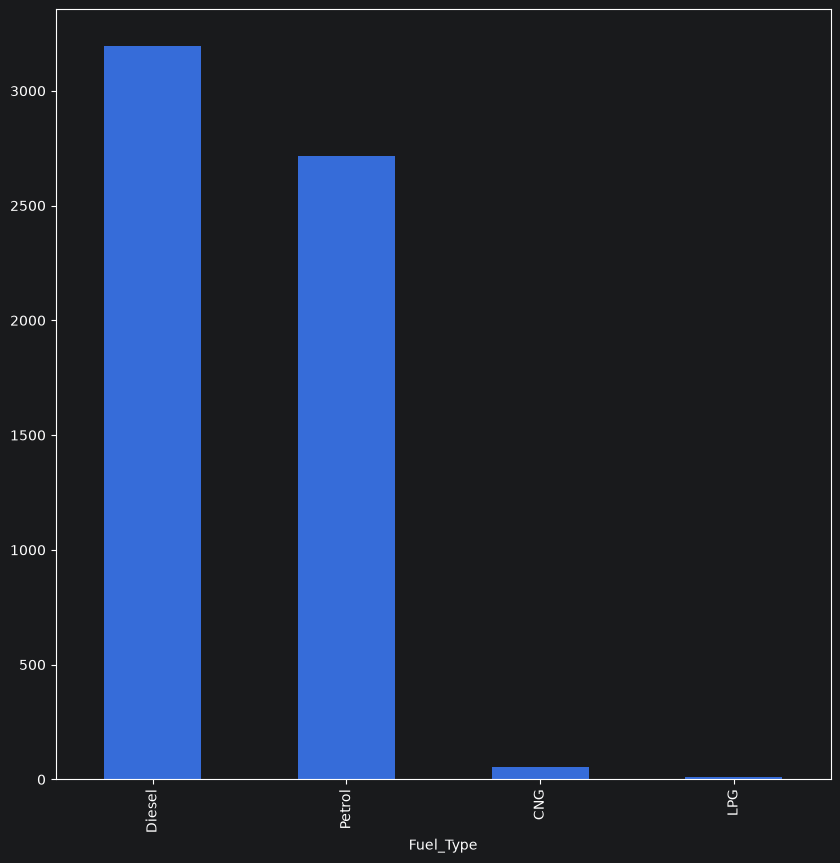

In [48]:
plt.figure(figsize=(10,10))
dataset['Fuel_Type'].value_counts().plot(kind='bar')

In [49]:
def types(type):
    if type =="Diesel":
        return "Diesel"
    elif type =="Petrol":
        return "Petrol"
    else:
        return "Other"

In [50]:
dataset ['Fuel_Type'] = dataset['Fuel_Type'].apply(types)

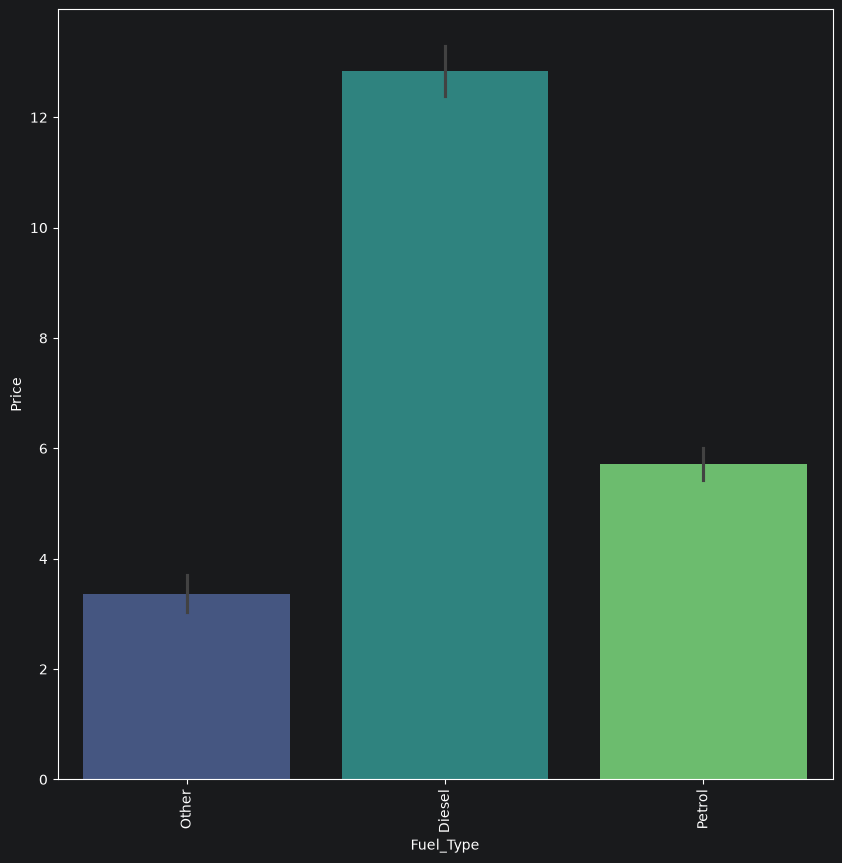

In [51]:
plt.figure(figsize=(10,10))
sns.barplot(data = dataset,x='Fuel_Type',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

<Axes: xlabel='count', ylabel='Transmission'>

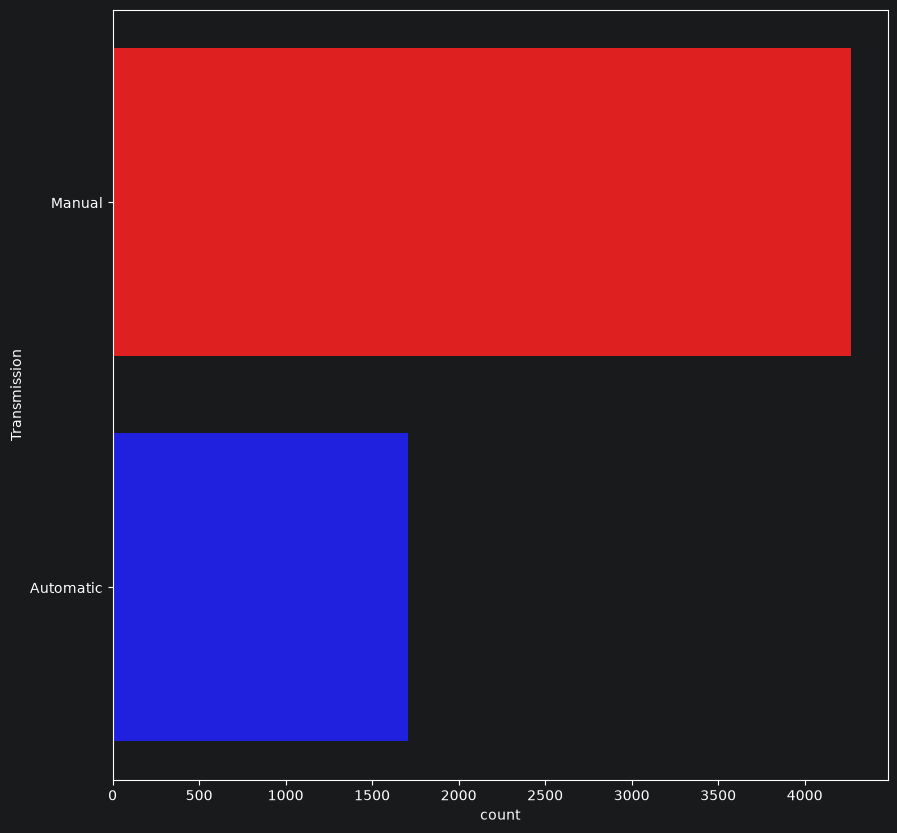

In [52]:
plt.figure(figsize=(10,10))
sns.countplot(dataset['Transmission'] , palette=['red','blue'])

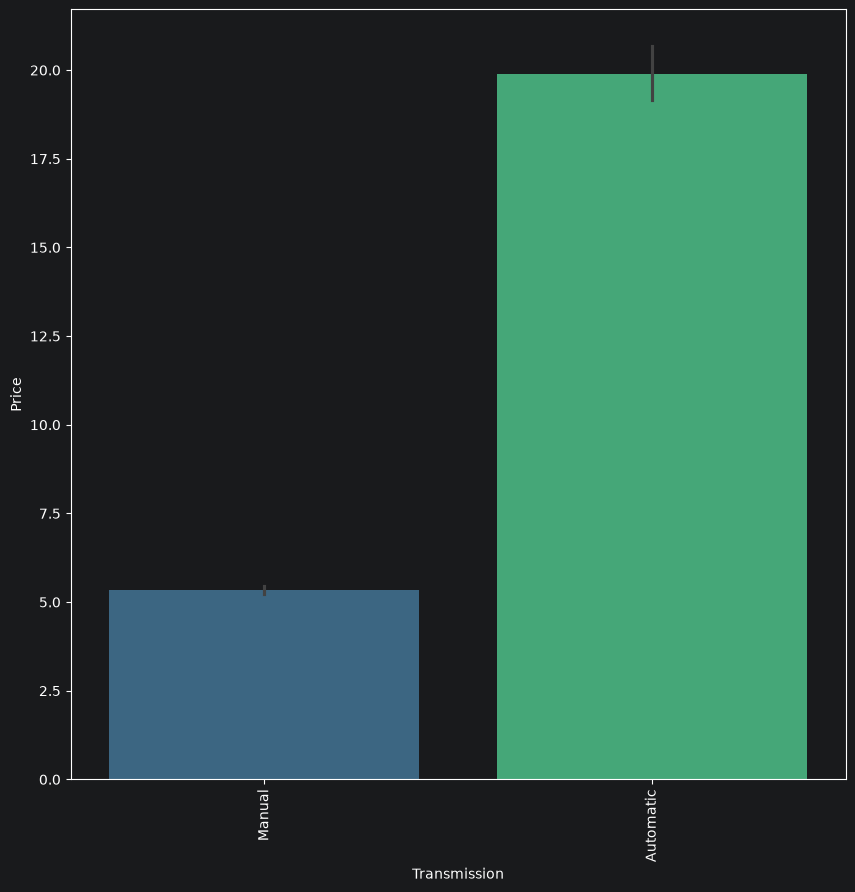

In [53]:
plt.figure(figsize=(10,10))
sns.barplot(data = dataset,x='Transmission',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

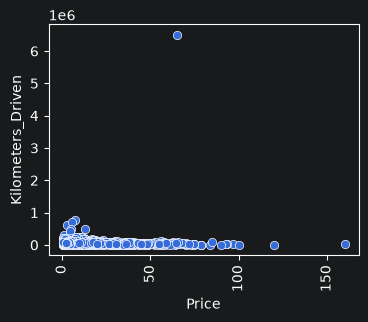

In [54]:
plt.figure(figsize=(4,3))
sns.scatterplot(data = dataset,x='Price',y='Kilometers_Driven',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

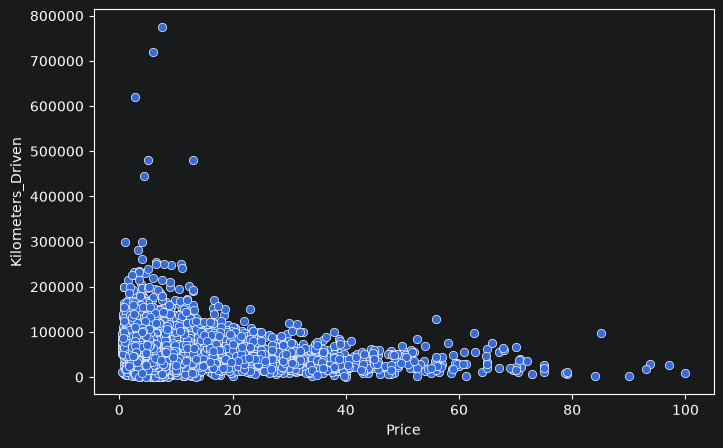

In [55]:
train_filtered = dataset[(dataset['Kilometers_Driven'] < 1000000) & (dataset['Price'] < 120)]

plt.figure(figsize=(8, 5))
sns.scatterplot(data=train_filtered, x='Price', y='Kilometers_Driven')
plt.show()

<Axes: xlabel='Owner_Type'>

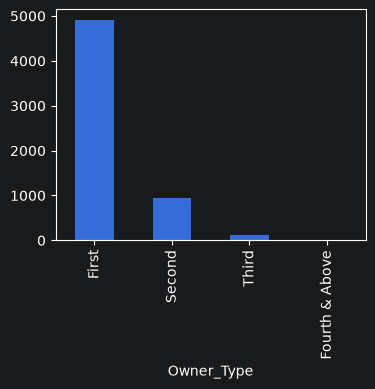

In [56]:
plt.figure(figsize=(4,3))
dataset['Owner_Type'].value_counts().plot(kind='bar')

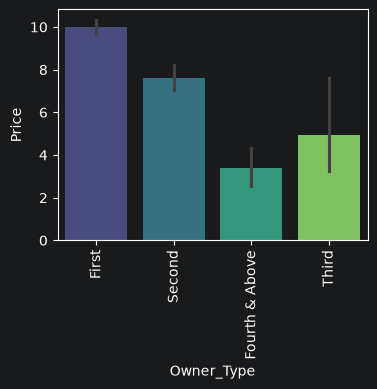

In [57]:
plt.figure(figsize=(4,3))
sns.barplot(data = dataset,x='Owner_Type',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

<Axes: xlabel='Seats'>

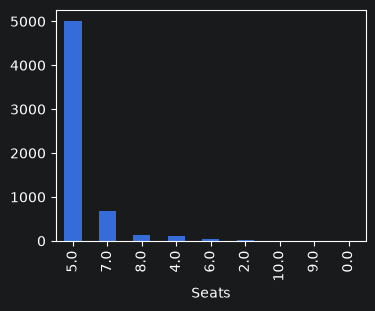

In [58]:
plt.figure(figsize=(4,3))
dataset['Seats'].value_counts().plot(kind='bar')

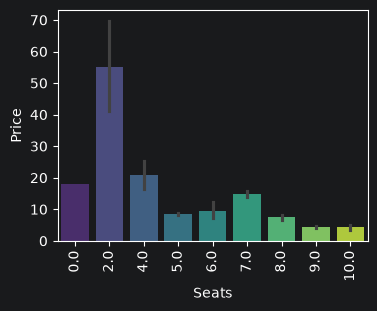

In [59]:
plt.figure(figsize=(4,3))
sns.barplot(data = dataset,x='Seats',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

In [60]:
dataset['Mileage'] = dataset['Mileage'].str.replace('kmpl','')
dataset['Mileage'] = dataset['Mileage'].str.replace('km/kg','')
dataset['Mileage'] = dataset['Mileage'].astype('float')

<Figure size 1000x500 with 0 Axes>

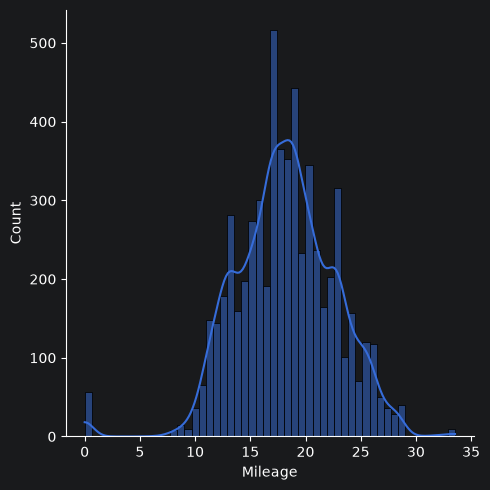

In [61]:
plt.figure(figsize=(10,5))
sns.displot(dataset['Mileage'],kde=True)

In [62]:
dataset = dataset[(dataset['Mileage'] > 0) & (dataset['Mileage'] < 30)]

<Figure size 2000x1000 with 0 Axes>

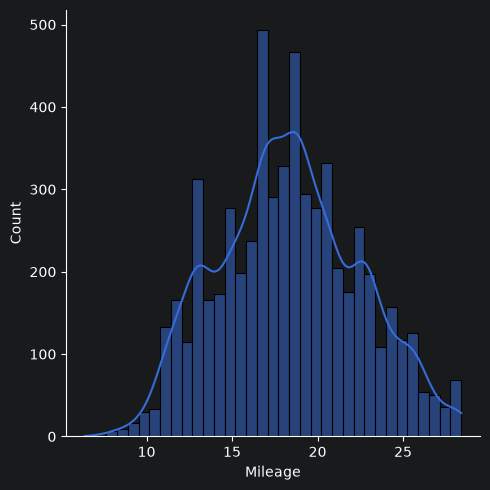

In [63]:
plt.figure(figsize=(20,10))
sns.displot(dataset['Mileage'],kde=True)

In [64]:
dataset['Engine'] = dataset['Engine'].str.replace('CC','').astype('int')

<Figure size 400x300 with 0 Axes>

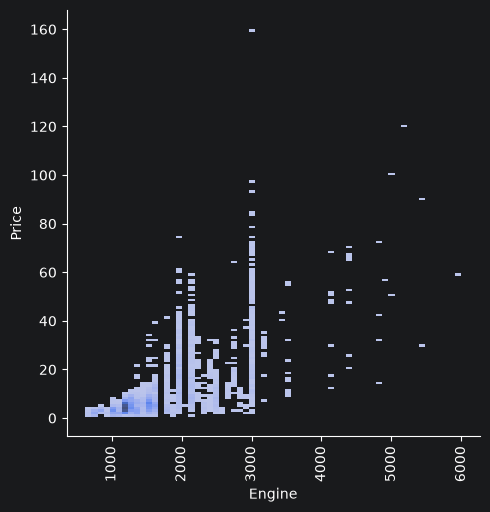

In [65]:
plt.figure(figsize=(4,3))
sns.displot(data = dataset,x='Engine',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

In [66]:
dataset['Power'] = dataset['Power'].str.replace('bhp','')

In [67]:
dataset[dataset['Power']=='null ']

,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
76,Ford Fiesta 1.4 SXi TDCi,Jaipur,2008,111111,Diesel,Manual,First,17.80,1399,null,5.0,2.00
89,Hyundai Santro Xing XO,Hyderabad,2007,73745,Petrol,Manual,First,17.00,1086,null,5.0,2.10
120,Hyundai Santro Xing XL eRLX Euro III,Mumbai,2005,102000,Petrol,Manual,Second,17.00,1086,null,5.0,0.85
143,Hyundai Santro Xing XO eRLX Euro II,Kochi,2008,80759,Petrol,Manual,Third,17.00,1086,null,5.0,1.67
227,Maruti Swift VDI BSIV,Delhi,2013,47000,Diesel,Manual,First,17.80,1248,null,5.0,4.10
...,...,...,...,...,...,...,...,...,...,...,...,...
5759,Hyundai Santro Xing XL eRLX Euro III,Kolkata,2007,46707,Petrol,Manual,First,17.00,1086,null,5.0,0.99
5861,Hyundai Santro Xing XO,Chennai,2007,79000,Petrol,Manual,First,17.00,1086,null,5.0,1.85
5873,Hyundai Santro Xing XO eRLX Euro II,Pune,2006,47200,Petrol,Manual,Second,17.00,1086,null,5.0,1.20
5925,Skoda Laura Classic 1.8 TSI,Pune,2010,85000,Petrol,Manual,First,17.50,1798,null,5.0,2.85


In [68]:
dataset['Power'] = dataset['Power'].replace('null ',np.nan)

In [69]:
dataset.dropna(inplace=True)

In [70]:
dataset['Power'] = dataset['Power'].astype('float')

<Axes: xlabel='Location'>

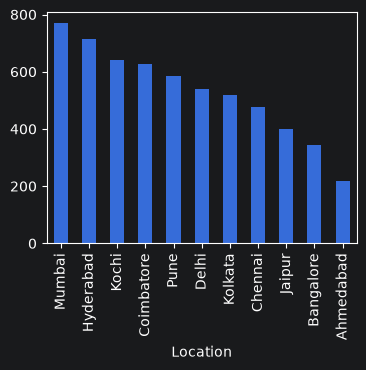

In [71]:
plt.figure(figsize=(4,3))
dataset['Location'].value_counts().plot(kind='bar')

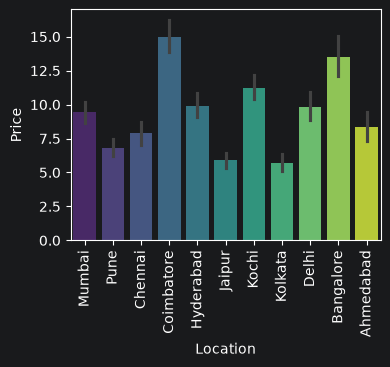

In [72]:
plt.figure(figsize=(4,3))
sns.barplot(data = dataset,x='Location',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()

In [73]:
dataset['Brand Name'] = dataset['Name'].apply(lambda x: x.split()[0])

In [74]:
dataset['Brand Name'] = dataset['Brand Name'].str.replace('Land','Land Rover')

In [75]:
dataset.drop('Name',axis=1,inplace=True)

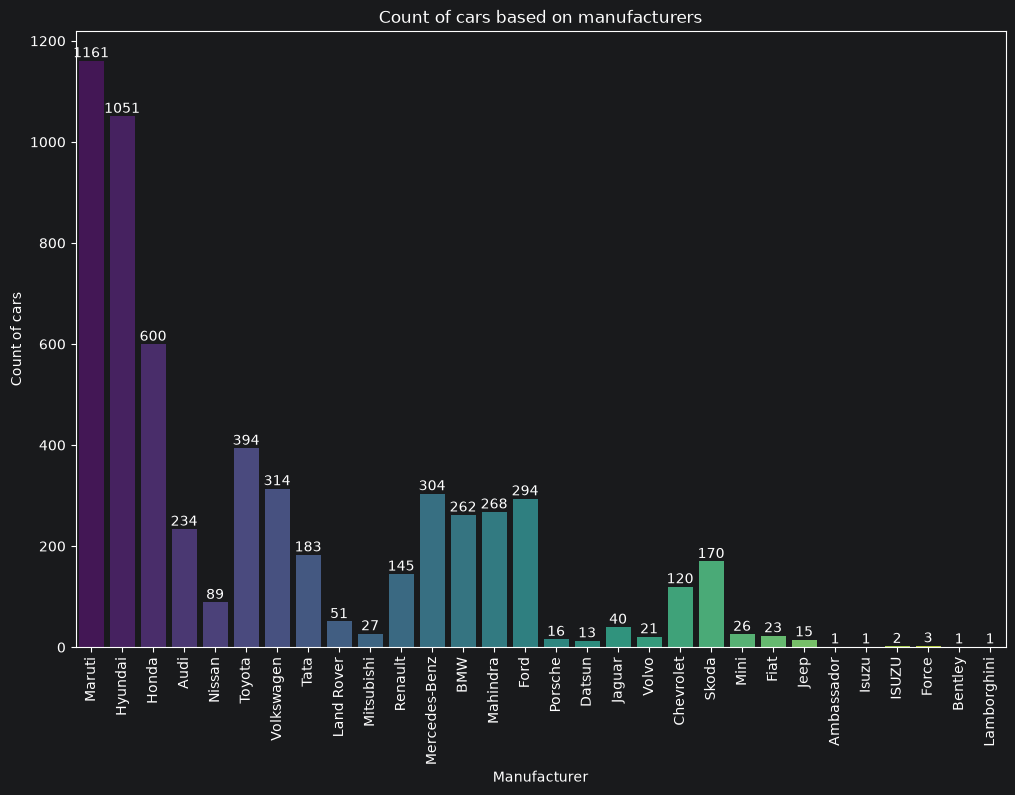

In [76]:
plt.figure(figsize=(12, 8))
plot = sns.countplot(x='Brand Name', data=dataset, palette='viridis')
plt.xticks(rotation=90)
for p in plot.patches:
    plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2.0,
                         p.get_height()),
                        ha = 'center',
                        va = 'center',
                        xytext = (0, 5),
                        textcoords = 'offset points')
plt.title("Count of cars based on manufacturers")
plt.xlabel("Manufacturer")
plt.ylabel("Count of cars")
plt.show()

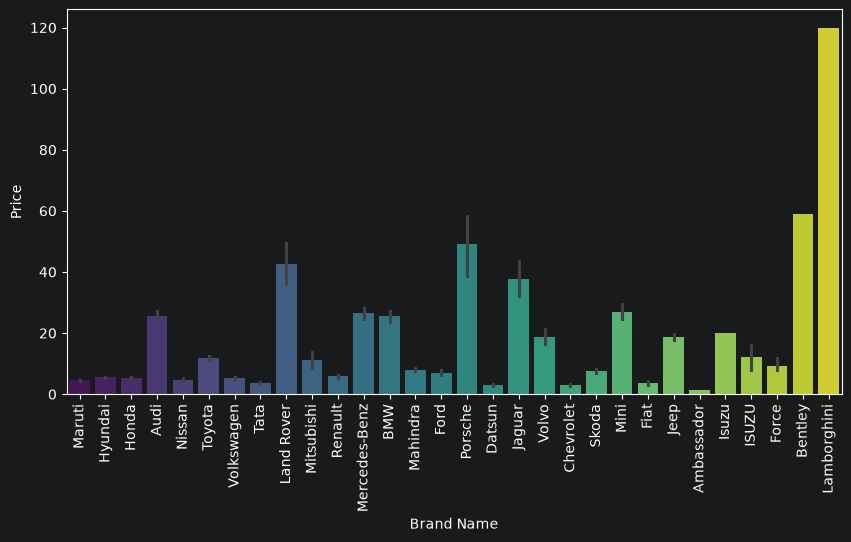

In [77]:
plt.figure(figsize=(10,5))
sns.barplot(data = dataset,x='Brand Name',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()


<Axes: xlabel='Year'>

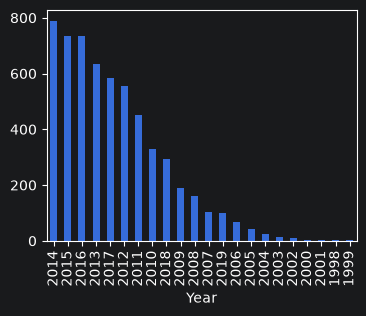

In [78]:
plt.figure(figsize=(4,3))
dataset['Year'].value_counts().plot(kind='bar')


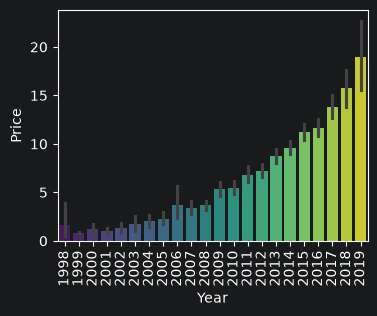

In [79]:
plt.figure(figsize=(4,3))
sns.barplot(data = dataset,x='Year',y='Price',palette='viridis')
plt.xticks(rotation='vertical')
plt.show()


In [80]:
dataset.head()

,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Brand Name
0,Mumbai,2010,72000,Other,Manual,First,26.60,998,58.16,5.0,1.75,Maruti
1,Pune,2015,41000,Diesel,Manual,First,19.67,1582,126.20,5.0,12.50,Hyundai
2,Chennai,2011,46000,Petrol,Manual,First,18.20,1199,88.70,5.0,4.50,Honda
3,Chennai,2012,87000,Diesel,Manual,First,20.77,1248,88.76,7.0,6.00,Maruti
4,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968,140.80,5.0,17.74,Audi


<Axes: >

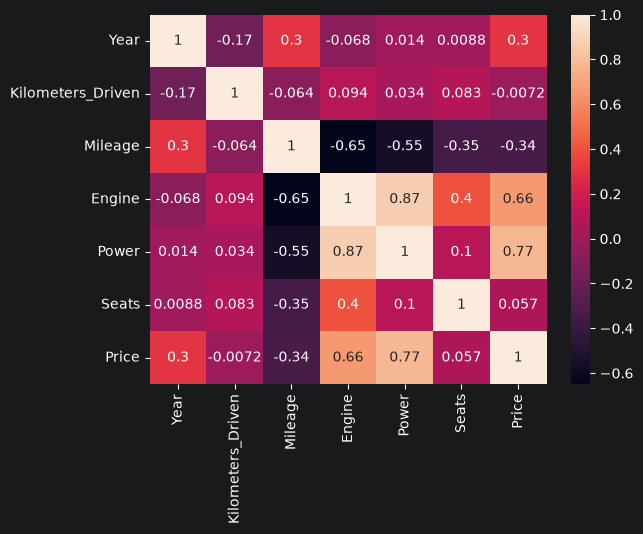

In [81]:
sns.heatmap(dataset.corr(numeric_only = True),annot=True)


In [82]:
dataset.to_csv("cleaned_train_data.csv", index=False)